In [5]:
import statistics as st
import numpy as np
import pandas as pd


df = pd.read_csv("autolevante_visitas.csv", sep=";")

nulos = pd.DataFrame({
    "Nulos": df.isna().sum(),
    "% del total": (df.isna().mean() * 100).round(1),
})

nulos[nulos["Nulos"] > 0].sort_values("Nulos", ascending=False)

#Con esto podemos observar que la descripcion es un valor inutil ya que esta el 60 % del campo nulo
#Aparte de que no nos dice nada la descripcion
#Lo




FileNotFoundError: [Errno 2] No such file or directory: 'autolevante_visitas.csv'

In [8]:
import pandas as pd
import statistics as st
import numpy as np

# Cargar tu dataset
df = pd.read_csv('/autolevante_visitas.csv')

print('=== 1. MILLAS VS. VUELVE DE AVERÍA ===')
# Media y mediana de millas según si vuelve de avería o no
stats_vuelve = (
    df.groupby('vuelve_averia')['millas']
    .agg(['count', 'mean', 'median', 'std'])
    .reset_index()
)
print(stats_vuelve)
print('\n' + '=' * 40 + '\n')



=== 1. MILLAS VS. VUELVE DE AVERÍA ===
  vuelve_averia  count           mean    median           std
0            No   1290   97414.227132   98658.0  46614.763438
1            Sí    310  118715.170968  119395.0  46818.885143




In [ ]:
print('=== 2. MILLAS VS. GRAVEDAD ===')
# Estadísticas de millas para cada nivel de gravedad de la avería
stats_gravedad = (
    df.groupby('gravedad')['millas']
    .agg(['count', 'mean', 'median', 'min', 'max'])
    .reset_index()
)
print(stats_gravedad)
print('\n' + '=' * 40 + '\n')

print('=== 3. COMBUSTIBLE VS. GRAVEDAD ===')
# Tabla cruzada (frecuencias) entre tipo de combustible y gravedad de la avería
tabla_cruzada = pd.crosstab(
    df['combustible'], df['gravedad'], margins=True, normalize='index'
) * 100  # En porcentaje por fila (opcional)
print('Porcentajes por tipo de combustible y gravedad (%):')
print(tabla_cruzada)

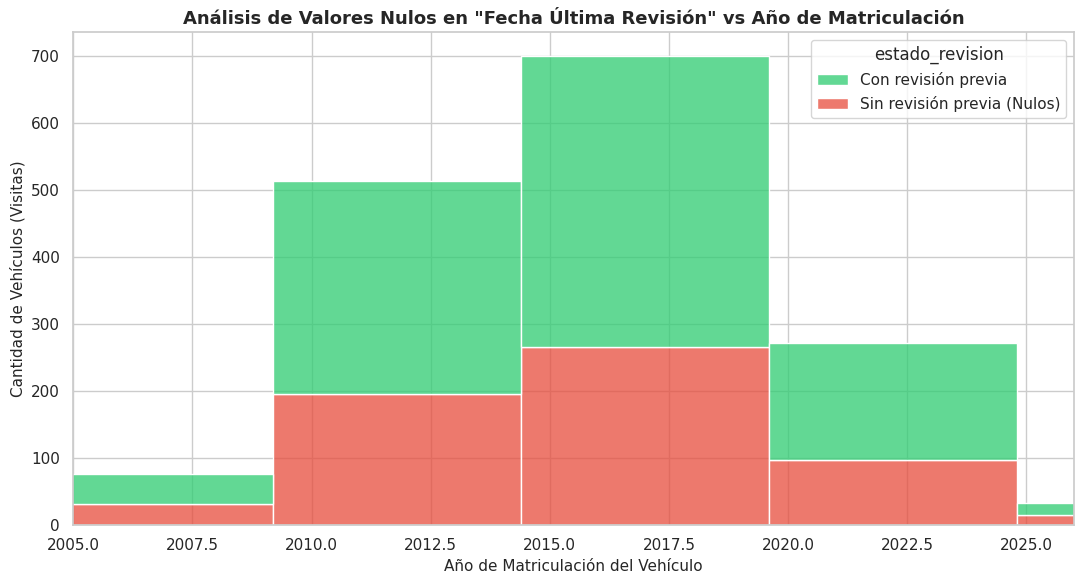

In [10]:
## Campo fecha_ultima-revision consideramos que es importante pero según vamos
## a ver, este campo contiene muchas cadenas vacías, a lo cual debemos
##tomar una decisión sobre como operar con este.

##Este campo es necesario porque el mantenimiento de un coche se rige por el tiempo
## los fabricantes establecen las previsiones segun el kilometraje el tiempo trascurrido
##tras la ultima revisión.

##DATO: POR LO GENERAL LOS COCHES DEBEN PASAR REVISIÓN COMPLETA AL MENOS UNA VEZ AL AÑO.

##PROBLEMA HAY MUCHOS VALORES NULOS.
##Porque?
##--> COches nuevos: VEhiculos que nunca han pasado por revision
##--> Falta de registro o error humano.
#Demostracion de este problema -->
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Cargar el dataset
df = pd.read_csv('/autolevante_visitas.csv')

# 2. Crear una etiqueta clara para distinguir los registros con y sin revisión
df['estado_revision'] = np.where(
    df['fecha_ultima_revision'].isnull(),
    'Sin revisión previa (Nulos)',
    'Con revisión previa',
)

# 3. Configurar el gráfico
plt.figure(figsize=(11, 6))
sns.set_theme(style='whitegrid')

# Gráfico de barras apiladas o histograma del año de matriculación
sns.histplot(
    data=df,
    x='anyo_matriculacion',
    hue='estado_revision',
    multiple='stack',
    palette=['#2ecc71', '#e74c3c'],  # Verde para con revisión, Rojo para nulos
    bins=25,
)

plt.title(
    'Análisis de Valores Nulos en "Fecha Última Revisión" vs Año de'
    ' Matriculación',
    fontsize=13,
    fontweight='bold',
)
plt.xlabel('Año de Matriculación del Vehículo', fontsize=11)
plt.ylabel('Cantidad de Vehículos (Visitas)', fontsize=11)

# Ajustar límites si hay valores muy antiguos extraños (como el año 1900 que vimos antes)
plt.xlim(2005, 2026)

plt.tight_layout()
plt.show()

=== TABLA DE RELACIÓN: AÑO DE MATRICULACIÓN VS REVISIÓN PREVIA ===
estado_revision     Con revisión previa  Sin revisión previa  Total
anyo_matriculacion                                                 
2005.0                                1                    3      4
2006.0                                4                    4      8
2007.0                                5                    2      7
2008.0                               10                    8     18
2009.0                               25                   15     40
2010.0                               32                   22     54
2011.0                               56                   27     83
2012.0                               58                   32     90
2013.0                               76                   53    129
2014.0                               95                   62    157
2015.0                              103                   58    161
2016.0                               94          

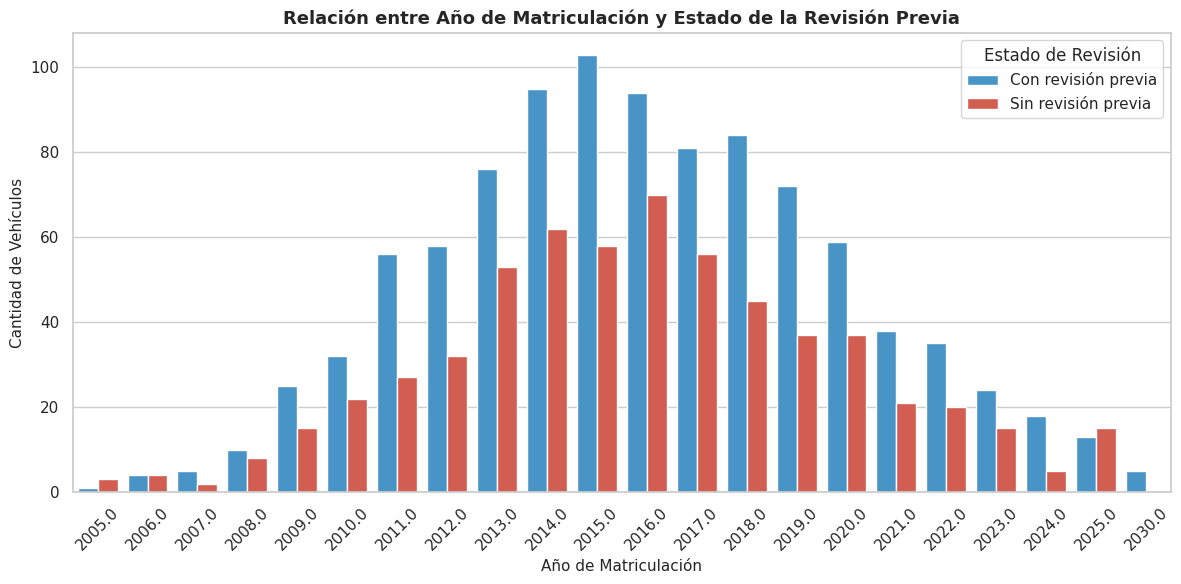

In [12]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Cargar el dataset
df = pd.read_csv('/autolevante_visitas.csv')

# 2. Crear la etiqueta clara del estado de la revisión
df['estado_revision'] = np.where(
    df['fecha_ultima_revision'].isnull(),
    'Sin revisión previa',
    'Con revisión previa',
)

# 3. Filtrar años extraños o erróneos (como el 1900 que vimos antes) para que la tabla sea limpia
df_filtrado = df[df['anyo_matriculacion'] >= 2005]

# 4. CREAR LA TABLA RELACIONADA (Años vs. Estado de Revisión)
tabla_relacion = pd.crosstab(
    df_filtrado['anyo_matriculacion'],
    df_filtrado['estado_revision'],
    margins=True,
    margins_name='Total',
)

print('=== TABLA DE RELACIÓN: AÑO DE MATRICULACIÓN VS REVISIÓN PREVIA ===')
print(tabla_relacion)

# 5. GENERAR GRÁFICO DE BARRAS AGRUPADAS PARA VISUALIZARLO
plt.figure(figsize=(12, 6))
sns.set_theme(style='whitegrid')

# Gráfico de barras usando countplot
sns.countplot(
    data=df_filtrado,
    x='anyo_matriculacion',
    hue='estado_revision',
    palette=['#3498db', '#e74c3c'],
)

plt.title(
    'Relación entre Año de Matriculación y Estado de la Revisión Previa',
    fontsize=13,
    fontweight='bold',
)
plt.xlabel('Año de Matriculación', fontsize=11)
plt.ylabel('Cantidad de Vehículos', fontsize=11)
plt.legend(title='Estado de Revisión')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
##NORMALIZACION DE DATOS

## Unificar el campo combustible

##